In [56]:
## Python Stuff
import os
import sys
import numpy as np
from array import array
import copy
import time
import matplotlib.pyplot as plt
import matplotlib
import json5 as json

import uproot

os.environ.get("ROOTSYS")

'/Users/austindestcroix/packages/root_py311_v6_26.10/myInstall_p311'

In [57]:
## ROOT stuff
import ROOT
from ROOT import TFile, TTree, TCanvas
from ROOT import TH1F, TH2F
import ctypes
import copy

ROOT.gStyle.SetCanvasDefW(600)
ROOT.gStyle.SetCanvasDefH(500)

# ROOT.gErrorIgnoreLevel = ROOT.kFatal
ROOT.gROOT.SetBatch(False)
# ROOT.enableJSVis()
# ROOT.disableJSVis()

## Atown's stuff
sys.path.append("..")
from globalsC2 import *
from helpers.anaStructs import * # includes SORTING class/namespace
from helpers.getSPE import *
import helpers.graphBuilders as GB

import MakeSpectra as MS
print(COMP2PATH)

saveFlag = False
save_dir = os.path.join(COMP2PATH, "DataAnalysis", "saved_spectra_ttnp")
print("\n-------\nSAVING OUTPUT TO:", save_dir)

/Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/comp2

-------
SAVING OUTPUT TO: /Users/austindestcroix/Desktop/school_holders/projects/sbc/CF4/comp2/DataAnalysis/saved_spectra_ttnp


---
### Cs - LP background runs

In [58]:
## loading run lists
rid_Cs_bkg = np.loadtxt(os.path.join(COMP2PATH, "runLists/CsLists/LPfilter_april_48V_background.txt"), dtype=str).tolist()
print(f"Loaded {len(rid_Cs_bkg)} runs for Cs background.")

runId, speValues, rc_Cs_LP_bkg, tFiles = MS.ExtractSPE(fileConfig=os.path.join(COMP2PATH, "pyScripts/files.json"), anaConfig=os.path.join(COMP2PATH, "pyScripts/speAnalysis.json"), argRunList=rid_Cs_bkg)
print(speValues[0][0].spe)

for rc in rc_Cs_LP_bkg:
  rc.print()

Loaded 7 runs for Cs background.
169.1605417589334

runID: 202204111213
Nevents: 14266.00,   time: 7.24 min
average Rate: 32.83 Hz
chID:0: spe = 169.16 +/- 0.58     maxChi2 = 12.58
chID:1: spe = 173.30 +/- 0.98     maxChi2 = 5.34
chID:2: spe = 173.41 +/- 0.62     maxChi2 = 6.48

runID: 202204111229
Nevents: 20738.00,   time: 9.70 min
average Rate: 35.64 Hz
chID:0: spe = 168.29 +/- 0.65     maxChi2 = 7.81
chID:1: spe = 174.12 +/- 0.65     maxChi2 = 5.89
chID:2: spe = 173.51 +/- 0.51     maxChi2 = 17.23

runID: 202204111247
Nevents: 12420.00,   time: 5.30 min
average Rate: 39.02 Hz
chID:0: spe = 167.68 +/- 0.64     maxChi2 = 10.31
chID:1: spe = 173.26 +/- 0.87     maxChi2 = 2.72
chID:2: spe = 172.65 +/- 0.67     maxChi2 = 22.01

runID: 202204111323
Nevents: 27391.00,   time: 12.92 min
average Rate: 35.33 Hz
chID:0: spe = 167.67 +/- 0.45     maxChi2 = 19.94
chID:1: spe = 173.51 +/- 0.69     maxChi2 = 6.67
chID:2: spe = 172.08 +/- 0.44     maxChi2 = 19.13

runID: 202204111434
Nevents: 2226

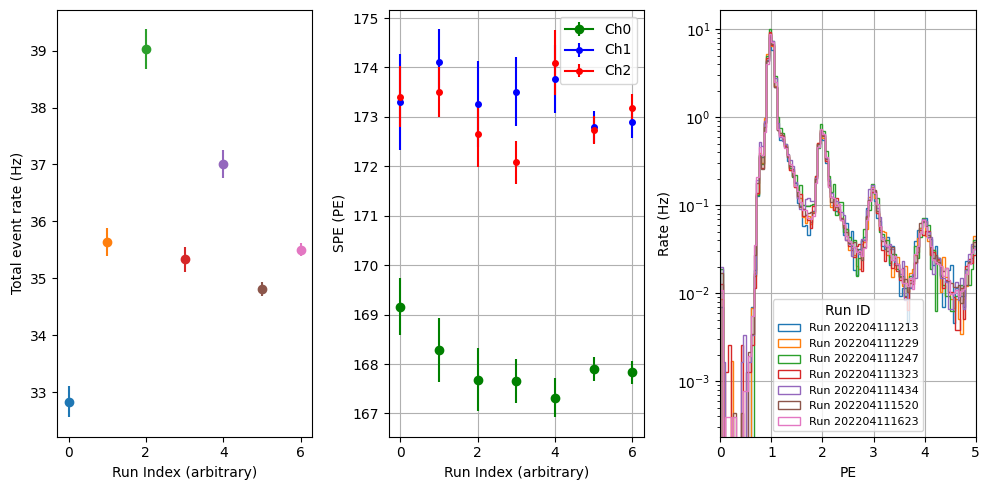

In [60]:
## plotting SPE vs background run
fig, (axrate, axspe, axbkg) = plt.subplots(1, 3, figsize=(10, 5))

anaCfg = MS.AnalysisConfig(os.path.join(COMP2PATH, "pyScripts/analysis.json"))

chCols = ["green", "blue", "red"]
for i, rc in enumerate(rc_Cs_LP_bkg):
  # rc.mpl_errorbar(axbkg, rate = True, label=f"Run {rc.id}", fmt='o', color=f"C{i}") 
  
  # axbkg.hist(x = rc.mBinX, bins = rc.mBin_edges, weights=rc.mBin_rawCounts)
  rc.mpl_hist(axbkg, rate=True, color=f"C{i}", label=f"Run {rc.id}", histtype='step')
  
  axrate.errorbar(i, rc.GetRate(), yerr=rc.GetRateError(), marker='o', color=f"C{i}", label=f"Run {rc.id}")
  for ich in range(anaCfg.nChan):
    chan = rc.GetChan(ich)
    label = None
    if i == 0:
      label = f"Ch{ich}"
    msize = 6 if ich == 0 else 4
    axspe.errorbar(i, chan.mSpe.spe, yerr=chan.mSpe.espe, marker = "o", markersize=msize, color=chCols[ich], label=label)

axrate.set_ylabel("Total event rate (Hz)")
axrate.set_xlabel("Run Index (arbitrary)")

axspe.legend()
axspe.set_ylabel("SPE (PE)")
axspe.set_xlabel("Run Index (arbitrary)")
axspe.grid()

axbkg.legend(title="Run ID", fontsize = 8)
axbkg.set_xlabel("PE")
axbkg.set_ylabel("Rate (Hz)")
axbkg.set_xlim(0, 5)
axbkg.set_yscale('log')
# axbkg.vlines((1, 2), ymin=1e-4, ymax=1e2, colors='gray', linestyles='dashed')
axbkg.grid()

# fig.suptitle("Cs Background Runs - LP Filtered Data at 48V")
plt.tight_layout(w_pad=1)
plt.show()

---
### Co - LP background runs

In [33]:
## loading run lists
rid_Co_bkg = np.loadtxt(os.path.join(COMP2PATH, "runLists/CoLists/LPfilter_april_48V_fineCol_bkg.txt"), dtype=str).tolist()
print(f"Loaded {len(rid_Co_bkg)} runs for Co background.")

runId, speValues, rc_Co_LP_bkg, tFiles = MS.ExtractSPE(fileConfig=os.path.join(COMP2PATH, "pyScripts/files.json"), anaConfig=os.path.join(COMP2PATH, "pyScripts/speAnalysis.json"), argRunList=rid_Co_bkg)

Loaded 7 runs for Co background.


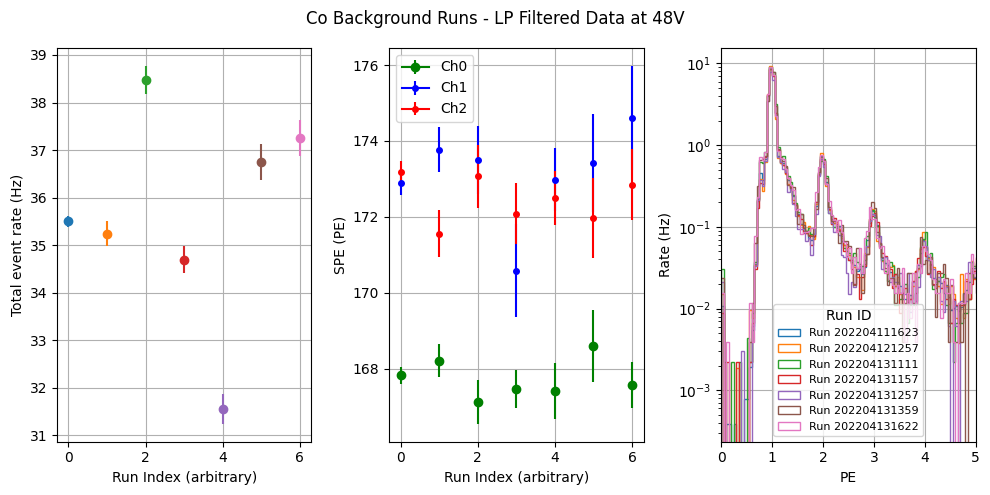

In [34]:
## plotting SPE vs background run
fig, (axrate, axspe, axbkg) = plt.subplots(1, 3, figsize=(10, 5))
anaCfg = MS.AnalysisConfig(os.path.join(COMP2PATH, "pyScripts/analysis.json"))

chCols = ["green", "blue", "red"]
for i, rc in enumerate(rc_Co_LP_bkg):
  
  axrate.errorbar(i, rc.GetRate(), yerr=rc.GetRateError(), marker='o', color=f"C{i}", label=f"Run {rc.id}")
  rc.mpl_hist(axbkg, rate=True, color=f"C{i}", label=f"Run {rc.id}", histtype='step')
  
  for ich in range(anaCfg.nChan):
    chan = rc.GetChan(ich)
    label = None
    if i == 0:
      label = f"Ch{ich}"
    msize = 6 if ich == 0 else 4
    axspe.errorbar(i, chan.mSpe.spe, yerr=chan.mSpe.espe, marker = "o", markersize=msize, color=chCols[ich], label=label)

axbkg.set_xlim(0, 10)
axbkg.set_yscale('log')

# axbkg.vlines((1, 2), ymin=1e-4, ymax=1e2, colors='gray', linestyles='dashed')

axrate.set_xlabel("Run Index (arbitrary)")
axrate.set_ylabel("Total event rate (Hz)")
axrate.grid()

axspe.legend()
axspe.set_ylabel("SPE (PE)")
axspe.set_xlabel("Run Index (arbitrary)")
axspe.grid()

axbkg.legend(title="Run ID", fontsize = 8)
axbkg.set_xlabel("PE")
axbkg.set_ylabel("Rate (Hz)")
axbkg.set_xlim(0, 5)
axbkg.grid()

fig.suptitle("Co Background Runs - LP Filtered Data at 48V")
plt.tight_layout()
plt.show()

In [35]:
print(type(rc_Co_LP_bkg[0].mttUp))
ttExample = rc_Co_LP_bkg[0].mttUp

print(ttExample.keys())

print(ttExample.show())

<class 'uproot.models.TTree.Model_TTree_v20'>
['chInfo', 'evTime', 'blineV', 'blineE', 'minV', 'timeMin', 'qFixed', 'qFlat', 'tFlatStart', 'tFlatEnd', 'qRCFixed', 'qRCFlat']
name                 | typename                 | interpretation                
---------------------+--------------------------+-------------------------------
chInfo               | int32_t[3]               | AsDtype("('>i4', (3,))")
evTime               | float                    | AsDtype('>f4')
blineV               | float[3]                 | AsDtype("('>f4', (3,))")
blineE               | float[3]                 | AsDtype("('>f4', (3,))")
minV                 | float[3]                 | AsDtype("('>f4', (3,))")
timeMin              | float[3]                 | AsDtype("('>f4', (3,))")
qFixed               | float[3]                 | AsDtype("('>f4', (3,))")
qFlat                | float[3]                 | AsDtype("('>f4', (3,))")
tFlatStart           | float[3]                 | AsDtype("('>f4', (3,))")

---
### Time between events (CA avalanche assesment)
* 2d histogram of time between events vs energy for all LP background runs

In [36]:
for i, rc in enumerate(rc_Cs_LP_bkg):
  rc.BuildCorrectEventTimes()

(14266, 3)
[1.24800000e+03 1.53059840e+07 4.17496640e+07 ... 4.14361218e+11
 4.14449344e+11 4.14450722e+11]
(14266,)


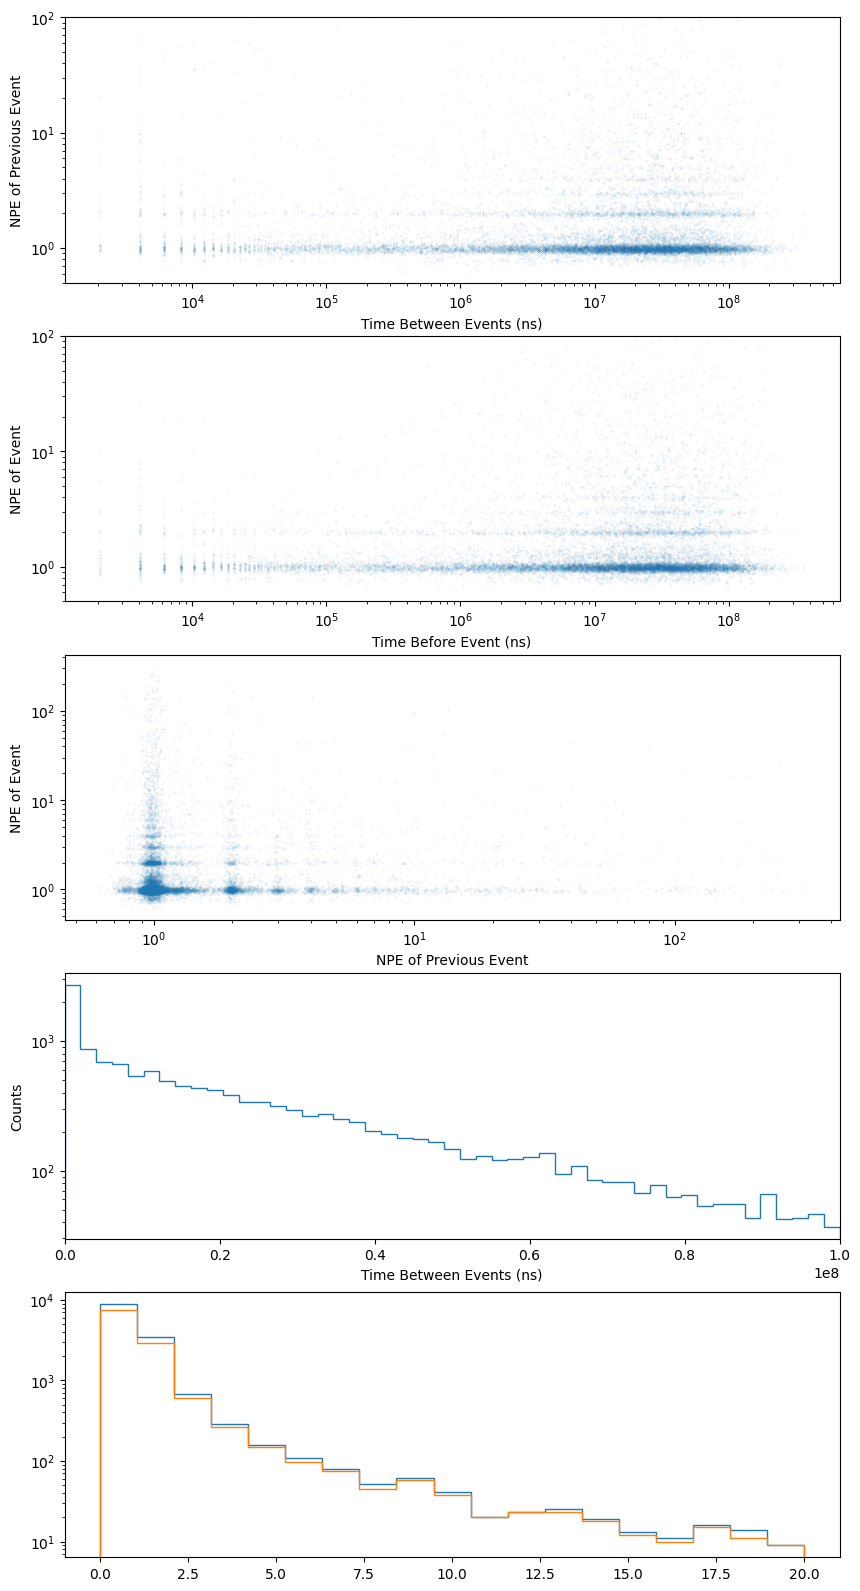

In [37]:
testRC = rc_Cs_LP_bkg[0]
evTime, pulseTimes, chanPE = testRC.BuildCorrectEventPulseTimes(qvar="qRCFlat", peCut=0.5)
t0 = evTime[0]

print(pulseTimes.shape)
maxPEindex = np.argmax(chanPE, axis = 1)
NPE = np.sum(chanPE, axis = 1)

biggestPulseTime = pulseTimes[np.arange(pulseTimes.shape[0]), maxPEindex]
peakPulseTimes = biggestPulseTime + evTime- t0
print(peakPulseTimes)

## okay can ignore pulse times for now, just use event times
evTime_BetweenEvents = np.diff(evTime)
pulseTimes_BetweenEvents = np.diff(peakPulseTimes)
print(evTime.shape)

fig, (ax1, ax1b, ax1c, ax2, ax3) = plt.subplots(5, 1, figsize=(10, 20))

## first plot is time between events vs NPE
ax1.plot(evTime_BetweenEvents, NPE[:-1], 'o', markersize=0.05)
# ax1.plot(pulseTimes_BetweenEvents, NPE[:-1], 'o', markersize=0.05, color='red', alpha  = 0.2)

ax1.set_xscale('log')
ax1.set_yscale('log')
ax1.set_ylim(0.5, 1e2)

ax1.set_xlabel("Time Between Events (ns)")
ax1.set_ylabel("NPE of Previous Event")

ax1b.plot(evTime_BetweenEvents, NPE[1:], 'o', markersize=0.05)
ax1b.set_xscale('log')
ax1b.set_yscale('log')
ax1b.set_ylim(0.5, 1e2)
ax1b.set_xlabel("Time Before Event (ns)")
ax1b.set_ylabel("NPE of Event")

ax1c.plot(NPE[:-1], NPE[1:], 'o', markersize=0.05)
ax1c.set_xlabel("NPE of Previous Event")
ax1c.set_ylabel("NPE of Event")

ax1c.set_xscale('log')
ax1c.set_yscale('log')

## ax2 is histogram of time between events
# bins2 = np.logspace(3, 6, 50)
bins2 = np.linspace(1e3, 1e8, 50)
ax2.hist(evTime_BetweenEvents, bins = bins2, histtype='step')

# ax2.set_xscale('log')
ax2.set_yscale('log')
ax2.set_xlabel("Time Between Events (ns)")
ax2.set_ylabel("Counts")
ax2.set_xlim(0, 1e8)

## ax3 is NPE with and without a cut on time between events
timeCut = 1e6 # ns
NPE_cut = NPE[1:][evTime_BetweenEvents > timeCut]

bin3 = np.linspace(0, 20, 20)
ax3.hist(NPE, bins = bin3, histtype='step', label="No Time Cut")
ax3.hist(NPE_cut, bins = bin3, histtype='step', label=f"Time Cut > {timeCut} ns")

ax3.set_yscale('log')

---
### rebinning all LP bkg spectra

In [38]:
MS.RebinRCObjects(rcList = rc_Co_LP_bkg + rc_Cs_LP_bkg, anaConfig=os.path.join(COMP2PATH, "pyScripts/analysis.json"))

---
### Averaging April (LP) backgrounds

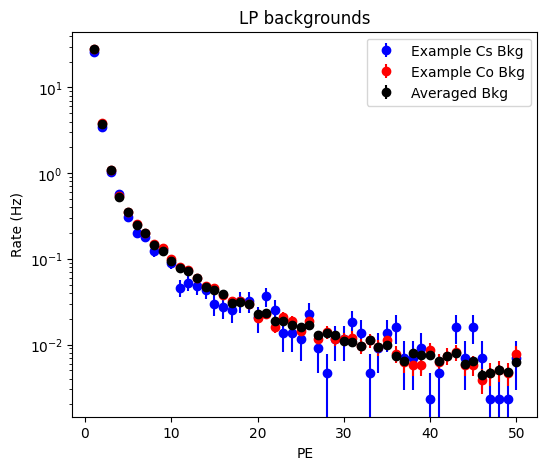

In [39]:
fig, axAvg = plt.subplots(1, 1, figsize=(6, 5))

rc_Cs_LP_bkg[0].mpl_errorbar(axAvg, rate = True, label="Example Cs Bkg", fmt='o', color='blue')
rc_Co_LP_bkg[0].mpl_errorbar(axAvg, rate = True, label="Example Co Bkg", fmt='o', color='red')

rcAvgBkg = RunClass.CombineRCs(name="avg_bkp_lp", rcList=rc_Cs_LP_bkg + rc_Co_LP_bkg)
rcAvgBkg.mpl_errorbar(axAvg, rate = True, label="Averaged Bkg", fmt='o', color='black')

axAvg.set_yscale('log')
axAvg.set_xlabel("PE")
axAvg.set_ylabel("Rate (Hz)")
axAvg.set_title("LP backgrounds")
axAvg.legend()

---
### Co LP source data

In [40]:
## loading run lists
rid_Co, heights_Co = np.loadtxt(os.path.join(COMP2PATH, "runLists/CoLists/LPfilter_april_48V_fineCol.txt"), dtype=str, delimiter=",", unpack=True)

runId, speValues, rc_Co_LP, tFiles = MS.ExtractSPE(argRunList=rid_Co, fileConfig=os.path.join(COMP2PATH, "pyScripts/files.json"), anaConfig=os.path.join(COMP2PATH, "pyScripts/speAnalysis.json"))

for rc, h in zip(rc_Co_LP, heights_Co):
  rc.mHeight = float(h)
  rc.print()
# print(f"Loaded {len(rid_Co_bkg)} runs for Co background.")


runID: 202204131513
Nevents: 167817.00,   time: 68.29 min
average Rate: 40.96 Hz
height = 26.00
chID:0: spe = 166.98 +/- 0.16     maxChi2 = 46.36
chID:1: spe = 173.06 +/- 0.33     maxChi2 = 28.84
chID:2: spe = 172.73 +/- 0.24     maxChi2 = 16.58

runID: 202204131317
Nevents: 111250.00,   time: 41.72 min
average Rate: 44.44 Hz
height = 28.50
chID:0: spe = 167.30 +/- 0.18     maxChi2 = 31.23
chID:1: spe = 172.73 +/- 0.37     maxChi2 = 37.30
chID:2: spe = 173.14 +/- 0.29     maxChi2 = 16.64

runID: 202204131122
Nevents: 130985.00,   time: 34.32 min
average Rate: 63.60 Hz
height = 30.50
chID:0: spe = 167.45 +/- 0.15     maxChi2 = 45.70
chID:1: spe = 172.63 +/- 0.33     maxChi2 = 5.25
chID:2: spe = 173.04 +/- 0.27     maxChi2 = 14.97


---
### Cs LP source data

In [41]:
## loading run lists
rid_Cs, heights_Cs = np.loadtxt(os.path.join(COMP2PATH, "runLists/CsLists/LPfilter_april_48V.txt"), dtype=str, delimiter=",", unpack=True)

runId, speValues, rc_Cs_LP, tFiles = MS.ExtractSPE(argRunList=rid_Cs, fileConfig=os.path.join(COMP2PATH, "pyScripts/files.json"), anaConfig=os.path.join(COMP2PATH, "pyScripts/speAnalysis.json"))

for rc, h in zip(rc_Cs_LP, heights_Cs):
  rc.mHeight = float(h)
  rc.print()


runID: 202204111600
Nevents: 52882.00,   time: 22.40 min
average Rate: 39.35 Hz
height = 26.00
chID:0: spe = 167.70 +/- 0.24     maxChi2 = 14.93
chID:1: spe = 172.90 +/- 0.38     maxChi2 = 10.64
chID:2: spe = 172.73 +/- 0.36     maxChi2 = 5.47

runID: 202204111454
Nevents: 60745.00,   time: 24.90 min
average Rate: 40.65 Hz
height = 28.50
chID:0: spe = 167.90 +/- 0.25     maxChi2 = 25.02
chID:1: spe = 172.84 +/- 0.35     maxChi2 = 12.47
chID:2: spe = 172.68 +/- 0.34     maxChi2 = 3.78

runID: 202204111423
Nevents: 29620.00,   time: 11.25 min
average Rate: 43.90 Hz
height = 30.50
chID:0: spe = 168.16 +/- 0.38     maxChi2 = 12.28
chID:1: spe = 173.19 +/- 0.49     maxChi2 = 13.53
chID:2: spe = 173.36 +/- 0.45     maxChi2 = 8.66

runID: 202204121321
Nevents: 51297.00,   time: 22.52 min
average Rate: 37.96 Hz
height = 32.00
chID:0: spe = 167.97 +/- 0.29     maxChi2 = 20.53
chID:1: spe = 173.15 +/- 0.37     maxChi2 = 19.06
chID:2: spe = 172.92 +/- 0.31     maxChi2 = 26.04


height is  1.5
(29620, 3)
[1.24800000e+03 4.92024320e+07 8.03176320e+07 ... 6.56734203e+11
 6.56736542e+11 6.56783271e+11]
(29620,)


/var/folders/1y/pq_0h029381_cwg2wmchsdt00000gn/T/ipykernel_77604/3160127850.py:60: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax2.set_xlim(0, 1e8)


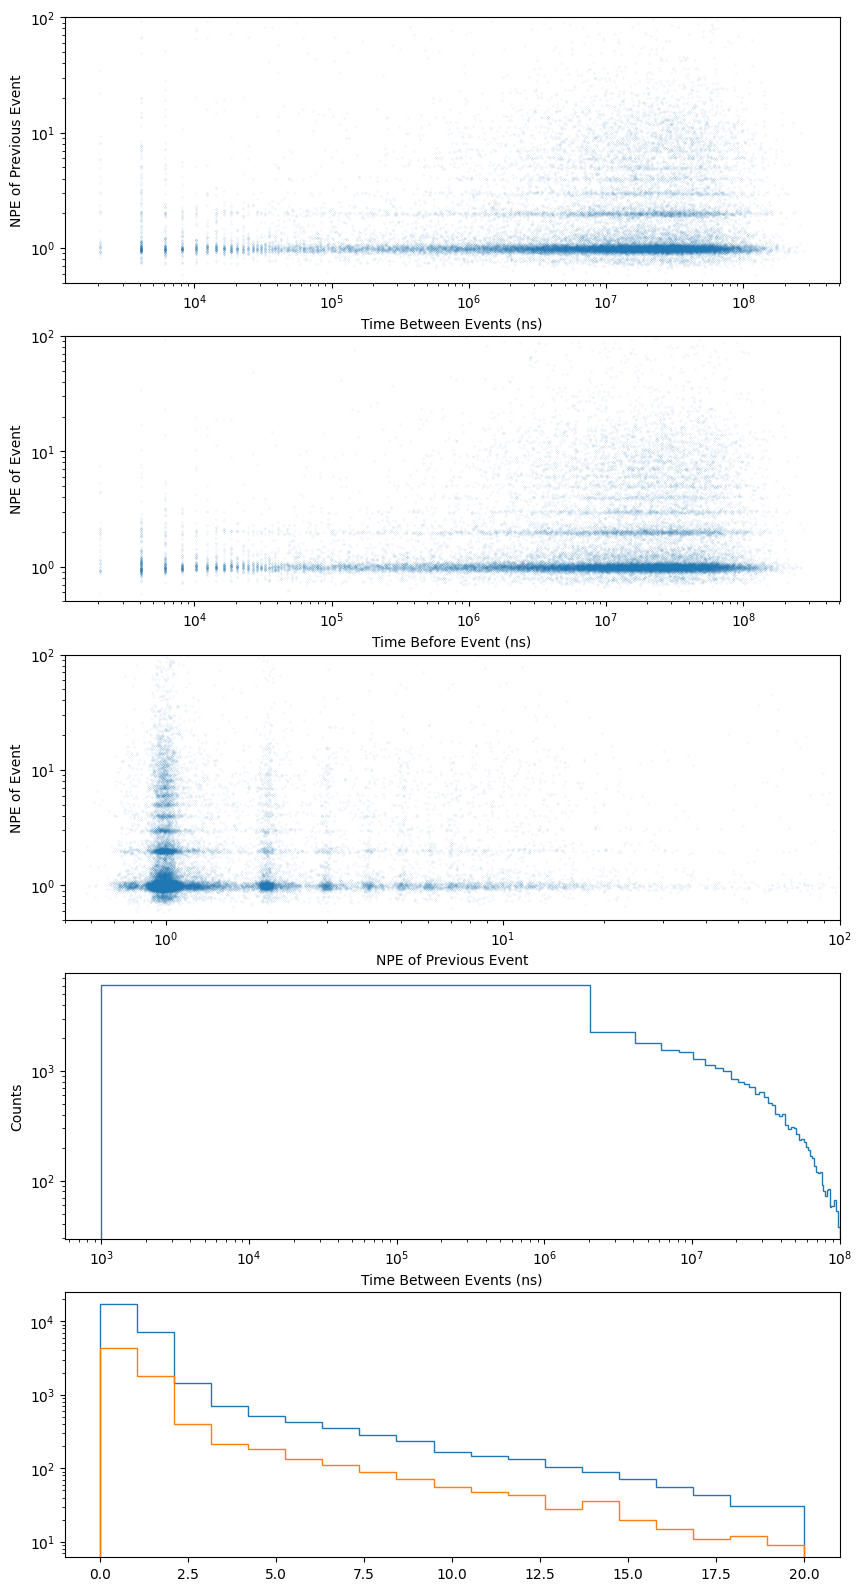

In [42]:
testRC = rc_Cs_LP[2]
testRC.BuildCorrectEventTimes()
print("height is ", 32 - testRC.mHeight)

evTime, pulseTimes, chanPE = testRC.BuildCorrectEventPulseTimes(qvar="qRCFlat", peCut=0.5)
t0 = evTime[0]

print(pulseTimes.shape)
maxPEindex = np.argmax(chanPE, axis = 1)
NPE = np.sum(chanPE, axis = 1)

biggestPulseTime = pulseTimes[np.arange(pulseTimes.shape[0]), maxPEindex]
peakPulseTimes = biggestPulseTime + evTime- t0
print(peakPulseTimes)

## okay can ignore pulse times for now, just use event times
evTime_BetweenEvents = np.diff(evTime)
pulseTimes_BetweenEvents = np.diff(peakPulseTimes)
print(evTime.shape)

fig, (ax1, ax1b, ax1c, ax2, ax3) = plt.subplots(5, 1, figsize=(10, 20))

## first plot is time between events vs NPE
ax1.plot(evTime_BetweenEvents, NPE[:-1], 'o', markersize=0.05)
# ax1.plot(pulseTimes_BetweenEvents, NPE[:-1], 'o', markersize=0.05, color='red', alpha  = 0.2)

ax1.set_xscale('log')
ax1.set_yscale('log')
ax1.set_ylim(0.5, 1e2)

ax1.set_xlabel("Time Between Events (ns)")
ax1.set_ylabel("NPE of Previous Event")

ax1b.plot(evTime_BetweenEvents, NPE[1:], 'o', markersize=0.05)
ax1b.set_xscale('log')
ax1b.set_yscale('log')
ax1b.set_ylim(0.5, 1e2)
ax1b.set_xlabel("Time Before Event (ns)")
ax1b.set_ylabel("NPE of Event")

ax1c.plot(NPE[:-1], NPE[1:], 'o', markersize=0.05)
ax1c.set_xlabel("NPE of Previous Event")
ax1c.set_ylabel("NPE of Event")

ax1c.set_xscale('log')
ax1c.set_yscale('log')
ax1c.set_xlim(0.5, 1e2)
ax1c.set_ylim(0.5, 1e2)

## ax2 is histogram of time between events
# bins2 = np.logspace(3, 6, 50)
bins2 = np.linspace(1e3, 1e8, 50)
ax2.hist(evTime_BetweenEvents, bins = bins2, histtype='step')
ax2.set_xscale('log')

# ax2.set_xscale('log')
ax2.set_yscale('log')
ax2.set_xlabel("Time Between Events (ns)")
ax2.set_ylabel("Counts")
ax2.set_xlim(0, 1e8)

## ax3 is NPE with and without a cut on time between events
timeCut = 3e7 # ns
NPE_cut = NPE[1:][evTime_BetweenEvents > timeCut]

bin3 = np.linspace(0, 20, 20)
ax3.hist(NPE, bins = bin3, histtype='step', label="No Time Cut")
ax3.hist(NPE_cut, bins = bin3, histtype='step', label=f"Time Cut > {timeCut} ns")

ax3.set_yscale('log')

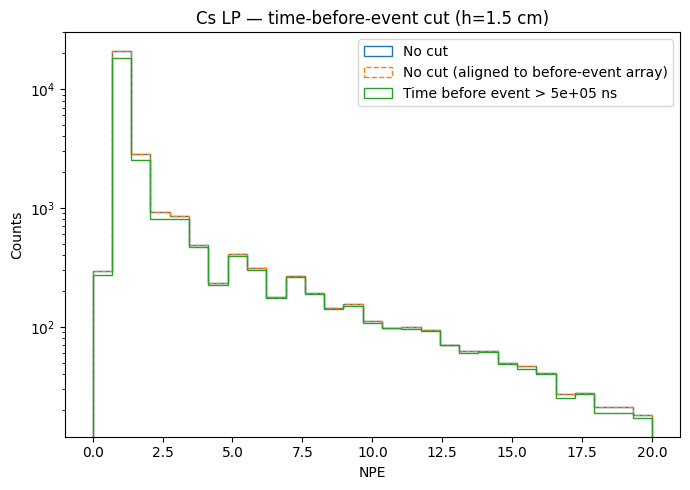

Events without cut: 29620
Events with time-before > 5e+05 ns: 26098 (88.1% kept)


In [64]:
## Time-before-event cut on Cs LP spectrum
# evTime_BetweenEvents[i] = time between event i and event i+1
# so "time before event i+1" = evTime_BetweenEvents[i]
# NPE[1:] are the events, evTime_BetweenEvents are the times before each of those events

timeCut_before = 5e5  # ns

mask_before = evTime_BetweenEvents > timeCut_before
NPE_cut_before = NPE[1:][mask_before]

fig, ax = plt.subplots(figsize=(7, 5))
bin_edges = np.linspace(0, 20, 30)

ax.hist(NPE, bins=bin_edges, histtype='step', label="No cut")
ax.hist(NPE[1:], bins=bin_edges, histtype='step', label="No cut (aligned to before-event array)", linestyle='dashed')
ax.hist(NPE_cut_before, bins=bin_edges, histtype='step', label=f"Time before event > {timeCut_before:.0e} ns")

ax.set_yscale('log')
ax.set_xlabel("NPE")
ax.set_ylabel("Counts")
ax.set_title(f"Cs LP — time-before-event cut (h={32 - testRC.mHeight:.1f} cm)")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Events without cut: {len(NPE)}")
print(f"Events with time-before > {timeCut_before:.0e} ns: {len(NPE_cut_before)} ({100*len(NPE_cut_before)/len(NPE[1:]):.1f}% kept)")


---
### rebinning source spectra

In [43]:
MS.RebinRCObjects(rcList = rc_Co_LP + rc_Cs_LP, anaConfig=os.path.join(COMP2PATH, "pyScripts/analysis.json"))

---
### Background Subtraction and Error Propagation
To subtract a scaled background from your data and properly propagate uncertainties, use the following formulas:

$$
N_{\text{signal}} = N_{\text{data}} - R_{\text{bkg}} \times t
$$

where:

- $N_{\text{data}}$ is the observed number of counts in the data run.
- $R_{\text{bkg}}$ is the background rate (Hz or counts/s).
- $t$ is the run time (s).

The total uncertainty on the expected background counts is:

$$
\sigma_{\text{Bkg}} = \sqrt{(t \cdot \sigma_{R_{\text{bkg}}})^2 + R_{\text{bkg}} \cdot t}
$$

where:

- $\sigma_{R_{\text{bkg}}}$ is the uncertainty on the background rate.
- $R_{\text{bkg}} \cdot t$ is the Poisson variance for the expected background counts (from counting statistics).

The total uncertainty on the background-subtracted signal is:

$$
\sigma_{\text{signal}} = \sqrt{N_{\text{data}} + \sigma_{\text{Bkg}}^2}
$$
This approach accounts for both the statistical uncertainty in the data and the propagated uncertainty from the scaled background.

---
### Co bkg subtraction

exists 22049.302909364375
exists 22401.34800509561
exists 57939.980435536076


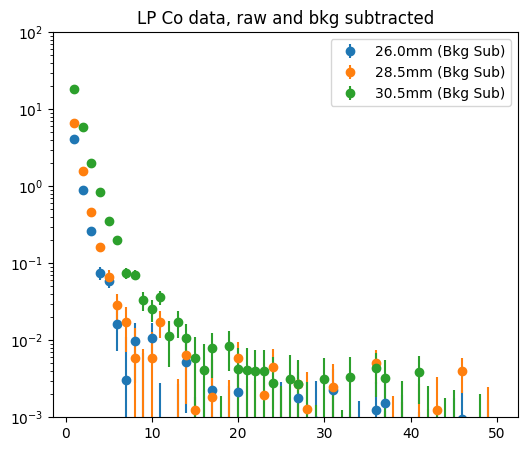

In [44]:
## uncorrected signal spectra
fig, axsig = plt.subplots(1, 1, figsize=(6, 5))

for rc in rc_Co_LP:
  # rc.BkgCorrected_spectrum(bkgRC=rcAvgBkg)
  # rc.mpl_errorbar(axsig, rate = True, bkgCorrected=False, label=f"{rc.mHeight}mm", marker='v', linestyle = "None")
  
  rc.BackgroundSubtraction(rcbkg=rcAvgBkg)
  rc.mpl_errorbar(axsig, rate = True, bkgCorrected=True, label=f"{rc.mHeight}mm (Bkg Sub)", marker = "o", linestyle = "None")

  print("exists", np.sum(rc.BkgCorrected_rawCounts))

# axsig.set_xlim(0, 5)
axsig.set_yscale('log')
axsig.set_ylim(1e-3, 1e2)
axsig.set_title("LP Co data, raw and bkg subtracted")
axsig.legend()
plt.show()

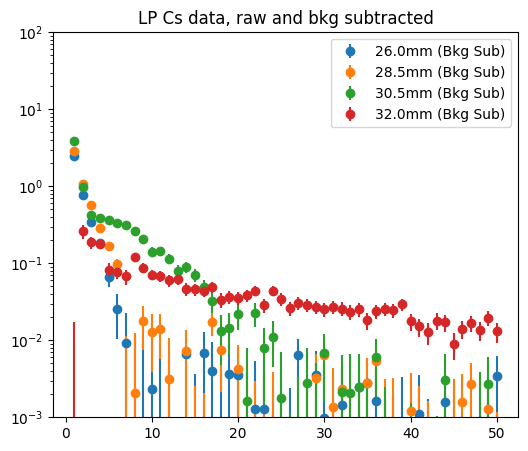

In [45]:
## uncorrected signal spectra
fig, axsig = plt.subplots(1, 1, figsize=(6, 5))
for rc in rc_Cs_LP:
  rc.BackgroundSubtraction(rcbkg=rcAvgBkg)
  rc.mpl_errorbar(axsig, rate = True, bkgCorrected=True, label=f"{rc.mHeight}mm (Bkg Sub)", marker = "o", linestyle = "None")

axsig.set_yscale('log')
axsig.set_ylim(1e-3, 1e2)
axsig.set_title("LP Cs data, raw and bkg subtracted")
axsig.legend()
plt.show()

---
## Bare data

In [46]:
## loading run lists for bare backgrounds (Co and Cs)
rid_Co_bare_bkg = np.loadtxt(os.path.join(COMP2PATH, "runLists/CoLists/bare_march_48V_bkg.txt"), dtype=str).tolist()
rid_Cs_bare_bkg = np.loadtxt(os.path.join(COMP2PATH, "runLists/CsLists/bare_march_48V_bkg.txt"), dtype=str).tolist()
print(f"Loaded {len(rid_Co_bare_bkg)} runs for Co bare background.")
print(f"Loaded {len(rid_Cs_bare_bkg)} runs for Cs bare background.")

runId, speValues, rc_Co_bare_bkg, tFiles = MS.ExtractSPE(fileConfig=os.path.join(COMP2PATH, "pyScripts/files.json"), anaConfig=os.path.join(COMP2PATH, "pyScripts/speAnalysis.json"), argRunList=rid_Co_bare_bkg)
runId, speValues, rc_Cs_bare_bkg, tFiles2 = MS.ExtractSPE(fileConfig=os.path.join(COMP2PATH, "pyScripts/files.json"), anaConfig=os.path.join(COMP2PATH, "pyScripts/speAnalysis.json"), argRunList=rid_Cs_bare_bkg)

Loaded 4 runs for Co bare background.
Loaded 7 runs for Cs bare background.


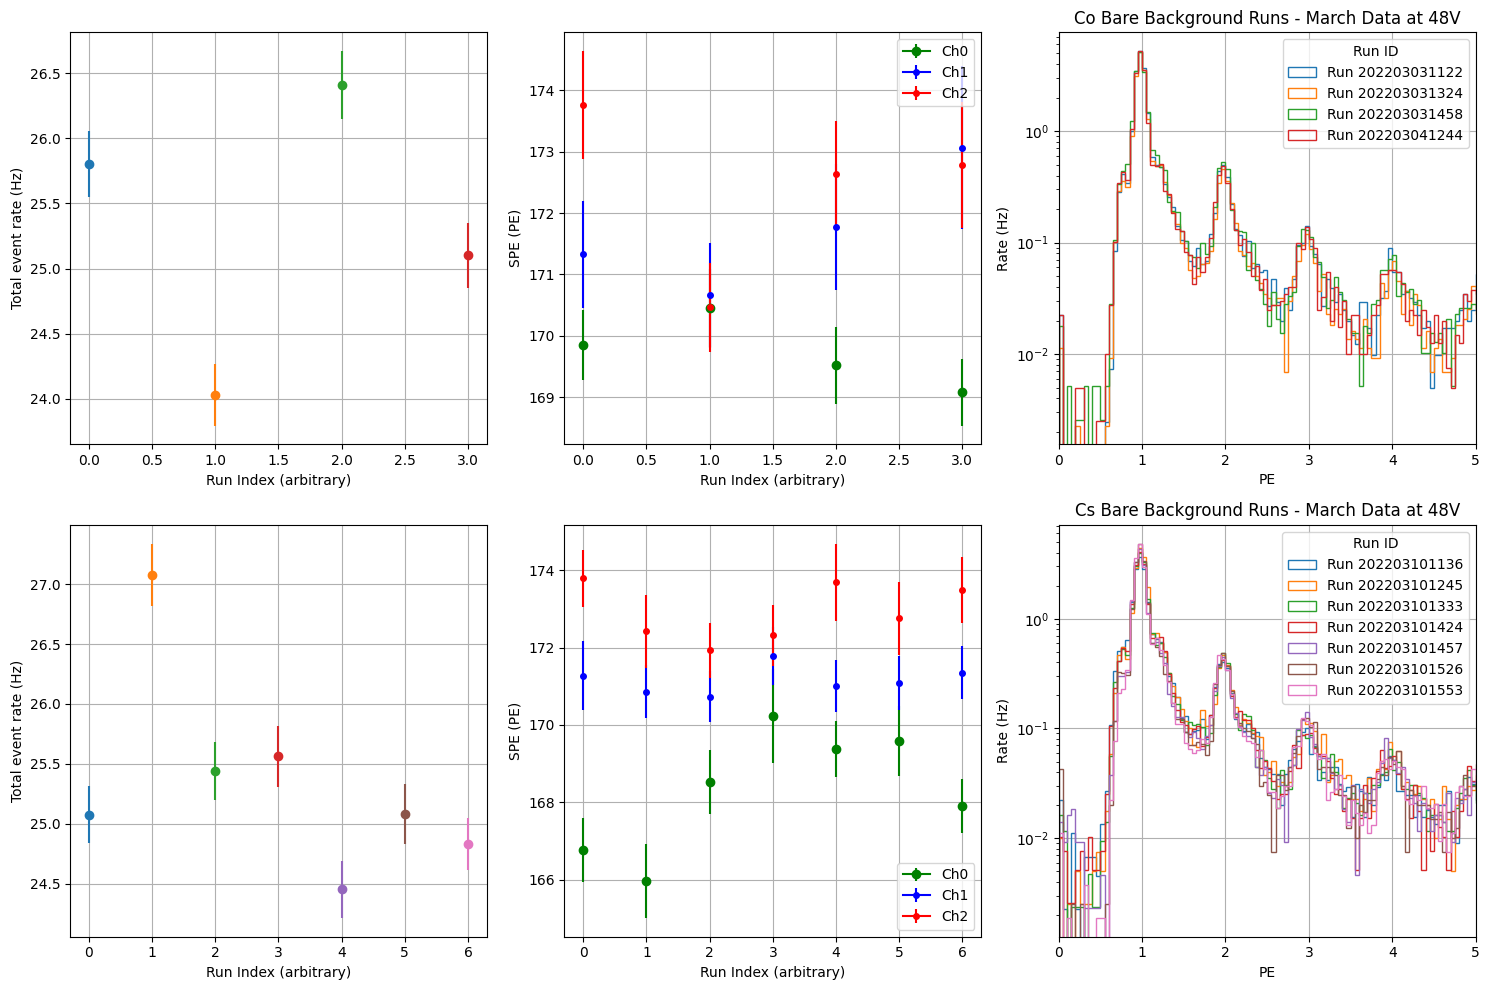

In [47]:
## plotting SPE vs background run for bare data (Co and Cs combined)
fig, ((axrate_co, axspe_co, axbkg_co), (axrate_cs, axspe_cs, axbkg_cs)) = plt.subplots(2, 3, figsize=(15, 10))

anaCfg = MS.AnalysisConfig(os.path.join(COMP2PATH, "pyScripts/analysis.json"))
chCols = ["green", "blue", "red"]

# Co bare backgrounds
for i, rc in enumerate(rc_Co_bare_bkg):
  rc.mpl_hist(axbkg_co, rate=True, color=f"C{i}", label=f"Run {rc.id}", histtype='step')
  axrate_co.errorbar(i, rc.GetRate(), yerr=rc.GetRateError(), marker='o', color=f"C{i}", label=f"Run {rc.id}")
  for ich in range(anaCfg.nChan):
    chan = rc.GetChan(ich)
    label = f"Ch{ich}" if i == 0 else None
    msize = 6 if ich == 0 else 4
    axspe_co.errorbar(i, chan.mSpe.spe, yerr=chan.mSpe.espe, marker="o", markersize=msize, color=chCols[ich], label=label)

# Cs bare backgrounds
for i, rc in enumerate(rc_Cs_bare_bkg):
  rc.mpl_hist(axbkg_cs, rate=True, color=f"C{i}", label=f"Run {rc.id}", histtype='step')
  axrate_cs.errorbar(i, rc.GetRate(), yerr=rc.GetRateError(), marker='o', color=f"C{i}", label=f"Run {rc.id}")
  for ich in range(anaCfg.nChan):
    chan = rc.GetChan(ich)
    label = f"Ch{ich}" if i == 0 else None
    msize = 6 if ich == 0 else 4
    axspe_cs.errorbar(i, chan.mSpe.spe, yerr=chan.mSpe.espe, marker="o", markersize=msize, color=chCols[ich], label=label)

# Co formatting
axrate_co.set_ylabel("Total event rate (Hz)")
axrate_co.set_xlabel("Run Index (arbitrary)")
axrate_co.grid()
axspe_co.legend()
axspe_co.set_ylabel("SPE (PE)")
axspe_co.set_xlabel("Run Index (arbitrary)")
axspe_co.grid()
axbkg_co.legend(title="Run ID")
axbkg_co.set_xlabel("PE")
axbkg_co.set_ylabel("Rate (Hz)")
axbkg_co.set_xlim(0, 5)
axbkg_co.set_yscale('log')
axbkg_co.grid()
axbkg_co.set_title("Co Bare Background Runs - March Data at 48V")

# Cs formatting
axrate_cs.set_ylabel("Total event rate (Hz)")
axrate_cs.set_xlabel("Run Index (arbitrary)")
axrate_cs.grid()
axspe_cs.legend()
axspe_cs.set_ylabel("SPE (PE)")
axspe_cs.set_xlabel("Run Index (arbitrary)")
axspe_cs.grid()
axbkg_cs.legend(title="Run ID")
axbkg_cs.set_xlabel("PE")
axbkg_cs.set_ylabel("Rate (Hz)")
axbkg_cs.set_xlim(0, 5)
axbkg_cs.set_yscale('log')
axbkg_cs.grid()
axbkg_cs.set_title("Cs Bare Background Runs - March Data at 48V")

plt.tight_layout()
plt.show()

---
### rebinning all bare bkg spectra

In [48]:
MS.RebinRCObjects(rcList = rc_Co_bare_bkg + rc_Cs_bare_bkg, anaConfig=os.path.join(COMP2PATH, "pyScripts/analysis.json"))

---
### Averaging bare (March) backgrounds

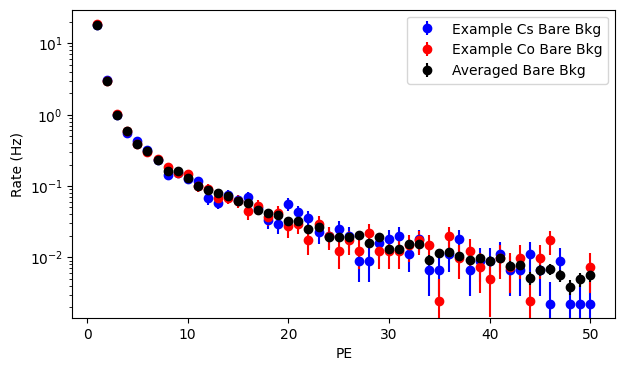

In [63]:
fig, axAvgBare = plt.subplots(1, 1, figsize=(7, 4))

rc_Cs_bare_bkg[0].mpl_errorbar(axAvgBare, rate = True, label="Example Cs Bare Bkg", fmt='o', color='blue')
rc_Co_bare_bkg[0].mpl_errorbar(axAvgBare, rate = True, label="Example Co Bare Bkg", fmt='o', color='red')

rcAvgBkg_bare = RunClass.CombineRCs(name="avg_bare_bkg", rcList=rc_Cs_bare_bkg + rc_Co_bare_bkg)
rcAvgBkg_bare.mpl_errorbar(axAvgBare, rate = True, label="Averaged Bare Bkg", fmt='o', color='black')

axAvgBare.set_yscale('log')
axAvgBare.set_xlabel("PE")
axAvgBare.set_ylabel("Rate (Hz)")

# axAvgBare.set_title("Bare backgrounds")
axAvgBare.legend()

---
### Bare source data (Co and Cs)

In [50]:
## loading bare source run lists for Co and Cs
rid_Co_bare, heights_Co_bare = np.loadtxt(os.path.join(COMP2PATH, "runLists/CoLists/bare_march_48V_fineCol.txt"), dtype=str, delimiter=",", unpack=True)
rid_Cs_bare, heights_Cs_bare = np.loadtxt(os.path.join(COMP2PATH, "runLists/CsLists/bare_march_48V_fineCol.txt"), dtype=str, delimiter=",", unpack=True)

runId, speValues, rc_Co_bare, tFiles = MS.ExtractSPE(argRunList=rid_Co_bare, fileConfig=os.path.join(COMP2PATH, "pyScripts/files.json"), anaConfig=os.path.join(COMP2PATH, "pyScripts/speAnalysis.json"))
runId, speValues, rc_Cs_bare, tFiles = MS.ExtractSPE(argRunList=rid_Cs_bare, fileConfig=os.path.join(COMP2PATH, "pyScripts/files.json"), anaConfig=os.path.join(COMP2PATH, "pyScripts/speAnalysis.json"))

for rc, h in zip(rc_Co_bare, heights_Co_bare):
  rc.mHeight = float(h)
  print(rc.GetSPE(0), rc.GetSPE(1), rc.GetSPE(2))

for rc, h in zip(rc_Cs_bare, heights_Cs_bare):
  rc.mHeight = float(h)
  print(rc.GetSPE(0), rc.GetSPE(1), rc.GetSPE(2))

169.60659620902052 171.95416399747083 173.07838725694958
169.1495189344354 171.65866736218032 172.95495396289195
169.82082958377825 171.57697563657518 172.75968679508142
169.92195651135103 171.76217801900583 173.3130327363215
169.48991372484386 170.99389838411452 172.70077164211682
168.95144970601598 171.12845852377905 172.33137953358067
169.0122702428009 171.12740343395814 172.15473676183046
168.59620676709238 170.92183551325616 171.6271536351549
168.96532898890837 171.51268274720252 172.1773963068604


---
### rebinning bare source spectra

In [51]:
MS.RebinRCObjects(rcList = rc_Co_bare + rc_Cs_bare, anaConfig=os.path.join(COMP2PATH, "pyScripts/analysis.json"))

---
### Co bare bkg subtraction

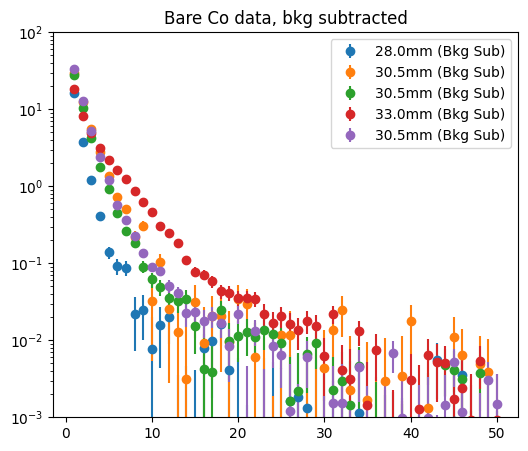

In [52]:
## bare Co signal spectra
fig, axsig_bare = plt.subplots(1, 1, figsize=(6, 5))

for rc in rc_Co_bare:
  rc.BackgroundSubtraction(rcbkg=rcAvgBkg_bare)
  rc.mpl_errorbar(axsig_bare, rate = True, bkgCorrected=True, label=f"{rc.mHeight}mm (Bkg Sub)", marker = "o", linestyle = "None")

axsig_bare.set_yscale('log')
axsig_bare.set_ylim(1e-3, 1e2)
axsig_bare.set_title("Bare Co data, bkg subtracted")
axsig_bare.legend()
plt.show()

---
### Cs bare bkg subtraction

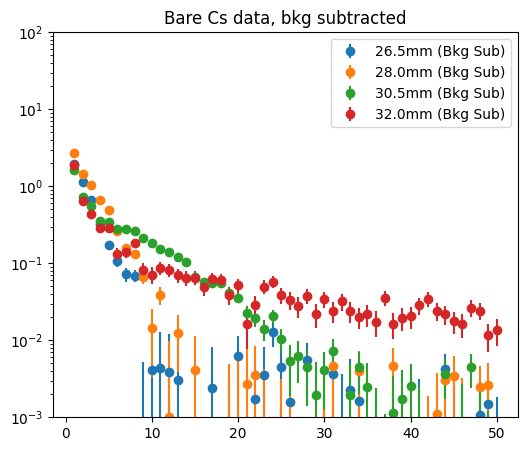

In [53]:
## bare Cs signal spectra
fig, axsig_bare_cs = plt.subplots(1, 1, figsize=(6, 5))

for rc in rc_Cs_bare:
  rc.BackgroundSubtraction(rcbkg=rcAvgBkg_bare)
  rc.mpl_errorbar(axsig_bare_cs, rate = True, bkgCorrected=True, label=f"{rc.mHeight}mm (Bkg Sub)", marker = "o", linestyle = "None")

axsig_bare_cs.set_yscale('log')
axsig_bare_cs.set_ylim(1e-3, 1e2)
axsig_bare_cs.set_title("Bare Cs data, bkg subtracted")
axsig_bare_cs.legend()
plt.show()

---
### Saving outputs

In [54]:
if saveFlag:
  # Save LP and Bare source RunClass lists via pickle using sanitized snapshots (no ROOT refs)
  import PickleLite as PL
  import pickle

  os.makedirs(save_dir, exist_ok=True)

  # Convert lists to snapshots
  rc_Co_LP_snap = [PL.runclass_snapshot(rc) for rc in rc_Co_LP]
  rc_Cs_LP_snap = [PL.runclass_snapshot(rc) for rc in rc_Cs_LP]
  rc_Co_bare_snap = [PL.runclass_snapshot(rc) for rc in rc_Co_bare]
  rc_Cs_bare_snap = [PL.runclass_snapshot(rc) for rc in rc_Cs_bare]

  # Pickle snapshots (portable, no ROOT objects)
  with open(os.path.join(save_dir, "rc_Co_LP_source.snap.pkl"), "wb") as f:
    pickle.dump(rc_Co_LP_snap, f, protocol=pickle.HIGHEST_PROTOCOL)
  with open(os.path.join(save_dir, "rc_Cs_LP_source.snap.pkl"), "wb") as f:
    pickle.dump(rc_Cs_LP_snap, f, protocol=pickle.HIGHEST_PROTOCOL)
  with open(os.path.join(save_dir, "rc_Co_bare_source.snap.pkl"), "wb") as f:
    pickle.dump(rc_Co_bare_snap, f, protocol=pickle.HIGHEST_PROTOCOL)
  with open(os.path.join(save_dir, "rc_Cs_bare_source.snap.pkl"), "wb") as f:
    pickle.dump(rc_Cs_bare_snap, f, protocol=pickle.HIGHEST_PROTOCOL)

  print("Saved ROOT sanitized snapshots for LP and Bare source RunClass lists via pickle.")